# SMS Spam Detection: TF-IDF vs Sentence-BERT

**ARTI 404 – Natural Language Processing | Section 7MA2 | Group 9**  
**Instructor:** Dr. Mohammed Mosuily  
**University:** Imam Abdulrahman Bin Faisal University

| Student | Student ID | Main work |
|---|---:|---|
| Mohammed Nasser Almarhoon (Team leader) | 2240005893 | Data preparation, TF-IDF model, its error analysis, GitHub repository and labelled examples |
| Ali Zuhair Alsaffar | 2240005706 | Sentence-BERT model, evaluation, comparison, interactive testing and its error analysis |

## What are we trying to do?

We use a short English SMS as input and predict whether it is **spam** or **not spam**. We compare two approaches:

1. TF-IDF features with Logistic Regression.
2. Sentence-BERT sentence embeddings with Logistic Regression.

Our main question is: **Which approach deals better with spam messages when words are misspelled or hidden using numbers and other substitutions?**

We also check whether the models mistakenly mark ordinary messages as spam, especially when those messages contain words that are often seen in spam.

## Notebook outline

1. Setup
2. Helper functions
3. Getting the data ready
4. Method 1 – TF-IDF with Logistic Regression
5. Method 2 – Sentence-BERT with Logistic Regression
6. Comparing the results
7. Looking at the mistakes
8. Try the models on a new message
9. Conclusion
10. Saving the results
11. Sources


## 1. Setup

We ran the notebook in Google Colab using Python. Sentence-BERT is the main library that may need to be installed. The dataset is read from the `data` folder when it is available; otherwise, the notebook downloads it from the UCI repository.

To repeat the experiment, choose **Runtime → Run all**. The first run may take a little longer because the pretrained Sentence-BERT model has to be downloaded.

In [1]:
# sentence-transformers is the only library that is not already installed on Colab
!pip install -q sentence-transformers

In [2]:
import os, re, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 120)

In [3]:
# package versions used in this run
import sys, sklearn, scipy, matplotlib, torch, sentence_transformers
print("python               ", sys.version.split()[0])
for name, mod in [("scikit-learn", sklearn), ("sentence-transformers", sentence_transformers), ("torch", torch),
                  ("pandas", pd), ("numpy", np), ("scipy", scipy), ("matplotlib", matplotlib)]:
    print(f"{name:21s}", mod.__version__)

python                3.13.18
scikit-learn          1.6.1
sentence-transformers 5.7.0
torch                 2.14.1+cpu
pandas                2.2.3
numpy                 2.4.6
scipy                 1.16.3
matplotlib            3.10.0


In [4]:
# Experiment settings
SEED       = 42                                  # main split
SEEDS      = [42, 1, 7, 21, 100]                 # for the 5-split experiment (6.6)
C_GRID     = [0.01, 0.1, 1, 10, 100, 1000]       # regularization values tried on dev
MIN_DF_GRID = [1, 2]                             # TF-IDF min document frequency tried on dev
P_LEVELS   = [0.0, 0.1, 0.25, 0.5]               # share of letters replaced in 6.3 / 6.4

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
UCI_URL    = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
LOCAL_FILE = "data/SMSSpamCollection.tsv"        # used instead of downloading if it exists

# spam-like words for rule 4 of the challenge subset
KEYWORDS = {"free", "win", "winner", "won", "prize", "claim", "cash", "urgent", "award", "awarded",
            "guaranteed", "bonus", "offer", "reward", "selected", "congratulations", "congrats"}

# letter substitutions used to obfuscate messages ourselves
LEET = {"e": "3", "i": "1", "o": "0", "a": "4", "s": "5"}

np.random.seed(SEED)

## 2. Helper functions

The next cell contains the small functions we use in different parts of the notebook. Keeping them together makes the later experiment cells easier to follow.

In [5]:
# Load the messages
def load_sms():
    """Load the SMS Spam Collection as a DataFrame with columns label, text."""
    if os.path.exists(LOCAL_FILE):
        txt = open(LOCAL_FILE, encoding="utf-8").read()
        print("loaded from", LOCAL_FILE)
    else:
        raw = urllib.request.urlopen(UCI_URL, timeout=30).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            txt = z.read("SMSSpamCollection").decode("utf-8")
        print("loaded from UCI")
    rows = [line.split("\t", 1) for line in txt.splitlines() if "\t" in line]
    return pd.DataFrame(rows, columns=["label", "text"])

# Model setup
def make_tfidf(min_df):
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=min_df, sublinear_tf=True)

def make_lr(C, seed, max_iter):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=max_iter, random_state=seed)

def macro_f1(y, p):
    return f1_score(y, p, average="macro")

# Rules used to select challenge messages
def tokens(t):
    return re.findall(r"[a-z0-9]+", t.lower())

def has_digit_in_word(t):     # rule 1: fr33, w1n, 2nite
    return any(re.search(r"[a-z]", w) and re.search(r"\d", w) for w in tokens(t))

def has_repeat(t):            # rule 2: sooo, freeee
    return re.search(r"([a-z])\1\1", t.lower()) is not None

def has_novowel(t):           # rule 3: txt, msg, pls
    return any(len(w) >= 3 and w.isalpha() and not re.search(r"[aeiouy]", w) for w in tokens(t))

def has_keyword(t):           # rule 4: free, win, prize ...
    return any(w in KEYWORDS for w in tokens(t))

def flags(t):
    return {"digit_in_word": has_digit_in_word(t), "repeat": has_repeat(t),
            "no_vowel": has_novowel(t), "keyword": has_keyword(t)}

# Create our own obfuscated versions
def leetify(t, p, rng):
    """Replace letters (e->3, i->1, o->0, a->4, s->5), each with probability p."""
    return "".join(LEET[c.lower()] if c.lower() in LEET and rng.random() < p else c for c in t)

# Statistical comparison
def mcnemar(y, p1, p2):
    """Exact McNemar test. b = only method 1 right, c = only method 2 right."""
    r1, r2 = (p1 == y), (p2 == y)
    b = int((r1 & ~r2).sum()); c = int((~r1 & r2).sum())
    pval = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, pval

## 3. Getting the data ready

### 3.1 Loading the data

We use the **UCI SMS Spam Collection**. It contains English text messages with two labels: `ham` for normal messages and `spam` for unwanted messages.

First, we load the file and have a quick look at its size and a few rows.

In [6]:
df = load_sms()
print(df.shape)
df.head()

loaded from UCI
(5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


label
ham     4827
spam     747
Name: count, dtype: int64


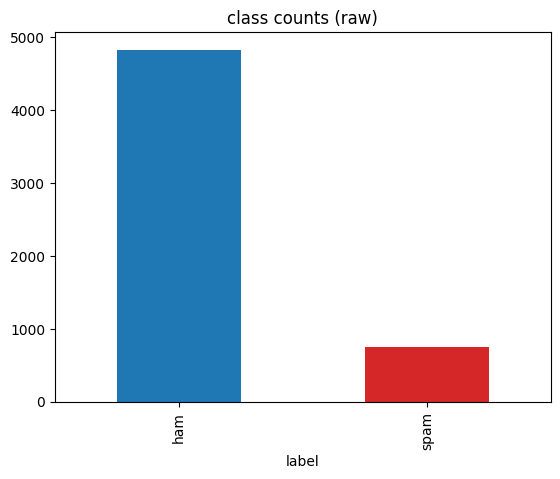

In [7]:
print(df["label"].value_counts())
df["label"].value_counts().plot(kind="bar", title="class counts (raw)", color=["tab:blue", "tab:red"])
plt.show()

### 3.2 Cleaning the messages

Before splitting the data, we remove leading and trailing spaces, empty messages and exact duplicate messages. We do this before the split so that a repeated message cannot appear in both the training set and the test set.

We use `0` for ham and `1` for spam.

In [8]:
n0 = len(df)
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]
n_empty = n0 - len(df)

n1 = len(df)
df = df.drop_duplicates(subset="text").reset_index(drop=True)
n_dup = n1 - len(df)

df["y"] = (df["label"] == "spam").astype(int)   # ham = 0, spam = 1

print("raw rows        :", n0)
print("empty removed   :", n_empty)
print("dupes removed   :", n_dup)
print("after cleaning  :", len(df))
print(df["label"].value_counts())
print("spam ratio      : %.3f" % df["y"].mean())

raw rows        : 5574
empty removed   : 0
dupes removed   : 414
after cleaning  : 5160
label
ham     4518
spam     642
Name: count, dtype: int64
spam ratio      : 0.124


### 3.3 Splitting the data

We split the cleaned data into training, development and test sets, using approximately 70%, 15% and 15%. Stratification keeps the spam/ham proportions similar in each part.

The training set is used to fit the models. We use the development set to choose settings, and keep the test set for the final comparison.

In [9]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
dev_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)

for name, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):5d} msgs | spam = {d['y'].sum():4d} ({d['y'].mean():.3f})")

X_train, y_train = train_df["text"].tolist(), train_df["y"].values
X_dev,   y_dev   = dev_df["text"].tolist(),   dev_df["y"].values
X_test,  y_test  = test_df["text"].tolist(),  test_df["y"].values

train:  3612 msgs | spam =  449 (0.124)
dev  :   774 msgs | spam =   97 (0.125)
test :   774 msgs | spam =   96 (0.124)


## 4. Method 1 – TF-IDF with Logistic Regression

For the first model, we turn each message into TF-IDF features. We use single words and two-word combinations (unigrams and bigrams). Logistic Regression then learns to classify the messages.

The dataset has many more normal messages than spam messages, so we use `class_weight="balanced"`. We try the listed `C` and `min_df` values on the development set and select the combination with the best macro F1 score.

In [10]:
m1_results = []
for min_df in MIN_DF_GRID:
    for C in C_GRID:
        vec = make_tfidf(min_df)
        clf = make_lr(C, SEED, 2000).fit(vec.fit_transform(X_train), y_train)
        p = clf.predict(vec.transform(X_dev))
        m1_results.append({"min_df": min_df, "C": C, "dev_acc": accuracy_score(y_dev, p), "dev_macroF1": macro_f1(y_dev, p)})

m1_tab = pd.DataFrame(m1_results).sort_values("dev_macroF1", ascending=False)
m1_tab

,min_df,C,dev_acc,dev_macroF1
4,1,100.00,0.984496,0.964641
10,2,100.00,0.984496,0.964325
9,2,10.00,0.983204,0.961863
3,1,10.00,0.980620,0.956377
8,2,1.00,0.980620,0.956377
5,1,1000.00,0.980620,0.956377
2,1,1.00,0.978036,0.950985
11,2,1000.00,0.978036,0.949685
0,1,0.01,0.975452,0.944745
1,1,0.10,0.974160,0.942088


In [11]:
best1 = m1_tab.iloc[0]
print("best on dev ->", dict(best1))

tfidf = make_tfidf(int(best1["min_df"]))
m1 = make_lr(float(best1["C"]), SEED, 2000).fit(tfidf.fit_transform(X_train), y_train)
print("vocab size:", len(tfidf.vocabulary_))

best on dev -> {'min_df': np.float64(1.0), 'C': np.float64(100.0), 'dev_acc': np.float64(0.9844961240310077), 'dev_macroF1': np.float64(0.9646408503251154)}
vocab size: 38364


In [12]:
# what the model learned: strongest words for spam and for ham
feat = np.array(tfidf.get_feature_names_out())
w = m1.coef_[0]
print("most spammy :", list(feat[np.argsort(w)[-20:][::-1]]))
print("most hammy  :", list(feat[np.argsort(w)[:20]]))

most spammy : ['call', 'txt', 'text', 'free', 'uk', 'reply', 'claim', 'stop', 'www', 'to', '150p', 'mobile', 'service', '50', 'prize', 'com', '146tf150p', 'won', 'ringtone', 'your']
most hammy  : ['me', 'my', 'your call', 'can', 'that', 'ok', 'gt', 'lt', 'but', 'it', 'lt gt', 'am', 'got', 'how', 'when', 'da', 'he', 'then', 'sorry', 'call me']


## 5. Method 2 – Sentence-BERT with Logistic Regression

For the second model, we use the pretrained `all-MiniLM-L6-v2` Sentence-BERT model. It converts each complete message into a 384-number sentence embedding. We keep Sentence-BERT frozen; we do not fine-tune it on this dataset.

We then train Logistic Regression on those embeddings. We use the same training and development messages as in Method 1, and choose `C` using the development macro F1 score.

In [13]:
sbert = SentenceTransformer(MODEL_NAME, device="cpu")
print("embedding size:", sbert.get_sentence_embedding_dimension())

def embed(texts):
    return sbert.encode(texts, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

# encoding takes about 1-2 minutes on the Colab CPU
E_train, E_dev, E_test = embed(X_train), embed(X_dev), embed(X_test)
print(E_train.shape, E_dev.shape, E_test.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

/tmp/ipykernel_1564/37804866.py:2: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("embedding size:", sbert.get_sentence_embedding_dimension())


embedding size: 384
(3612, 384) (774, 384) (774, 384)


In [14]:
m2_results = []
for C in C_GRID:
    p = make_lr(C, SEED, 5000).fit(E_train, y_train).predict(E_dev)
    m2_results.append({"C": C, "dev_acc": accuracy_score(y_dev, p), "dev_macroF1": macro_f1(y_dev, p)})

m2_tab = pd.DataFrame(m2_results).sort_values("dev_macroF1", ascending=False)
m2_tab

,C,dev_acc,dev_macroF1
4,100.00,0.984496,0.964950
5,1000.00,0.984496,0.964950
3,10.00,0.976744,0.949186
2,1.00,0.971576,0.938906
1,0.10,0.963824,0.923483
0,0.01,0.945736,0.888732


In [15]:
best2 = m2_tab.iloc[0]
print("best on dev ->", dict(best2))
m2 = make_lr(float(best2["C"]), SEED, 5000).fit(E_train, y_train)

best on dev -> {'C': np.float64(100.0), 'dev_acc': np.float64(0.9844961240310077), 'dev_macroF1': np.float64(0.9649498852795556)}


## 6. Comparing the results

### 6.1 Results on the test set

The model settings have now been selected using the development set. We can use the test set for the final comparison. Both models are evaluated on exactly the same test messages.

In [16]:
pred1 = m1.predict(tfidf.transform(X_test))
pred2 = m2.predict(E_test)

results = pd.DataFrame([
    {"method": "M1: TF-IDF + LR", "accuracy": accuracy_score(y_test, pred1), "macro_F1": macro_f1(y_test, pred1)},
    {"method": "M2: SBERT + LR",  "accuracy": accuracy_score(y_test, pred2), "macro_F1": macro_f1(y_test, pred2)},
]).round(4)
results

,method,accuracy,macro_F1
0,M1: TF-IDF + LR,0.9845,0.9640
1,M2: SBERT + LR,0.9780,0.9501


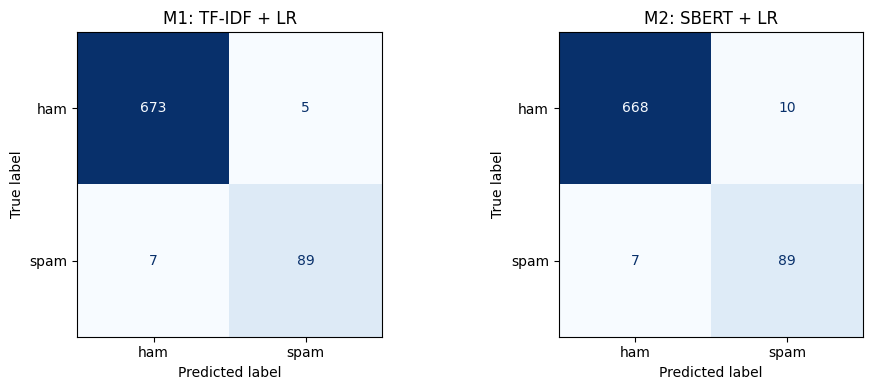

M1
               precision    recall  f1-score   support

         ham      0.990     0.993     0.991       678
        spam      0.947     0.927     0.937        96

    accuracy                          0.984       774
   macro avg      0.968     0.960     0.964       774
weighted avg      0.984     0.984     0.984       774

M2
               precision    recall  f1-score   support

         ham      0.990     0.985     0.987       678
        spam      0.899     0.927     0.913        96

    accuracy                          0.978       774
   macro avg      0.944     0.956     0.950       774
weighted avg      0.978     0.978     0.978       774



In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, p, t in [(ax[0], pred1, "M1: TF-IDF + LR"), (ax[1], pred2, "M2: SBERT + LR")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["ham", "spam"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(t)
plt.tight_layout(); plt.show()

print("M1\n", classification_report(y_test, pred1, target_names=["ham", "spam"], digits=3))
print("M2\n", classification_report(y_test, pred2, target_names=["ham", "spam"], digits=3))

### 6.2 Checking messages that may be difficult

We made a small set of rules to find messages that might contain misspellings, unusual spelling or spam-related words. A message is included if it matches at least one rule:

1. A word contains both letters and digits, for example `fr33` or `w1n`.
2. A letter is repeated three or more times, for example `sooo`.
3. A word has at least three letters and no vowel, for example `txt` or `msg`.
4. The message contains one of our spam-related keywords, such as `free`, `win`, `prize` or `claim`.

The fourth rule can also select normal messages. We keep it because we want to see whether the models are affected by spam-like words when they appear in an ordinary message. We also report a smaller group using only the first three rules.

In [18]:
F = pd.DataFrame([flags(t) for t in X_test], index=test_df.index)
test_df = test_df.join(F)
test_df["obfuscated"] = F[["digit_in_word", "repeat", "no_vowel"]].any(axis=1)
test_df["challenge"]  = F.any(axis=1)
test_df["pred1"], test_df["pred2"] = pred1, pred2

print("flag counts on test set:")
print(F.sum())
print("\nchallenge subset size:", test_df["challenge"].sum(), "of", len(test_df))
print(pd.crosstab(test_df["challenge"], test_df["label"]))

flag counts on test set:
digit_in_word     92
repeat            23
no_vowel         121
keyword           63
dtype: int64

challenge subset size: 205 of 774
label      ham  spam
challenge           
False      554    15
True       124    81


In [19]:
# a few flagged examples, to check that the rules make sense
test_df[test_df["challenge"]][["label", "text", "digit_in_word", "repeat", "no_vowel", "keyword"]].sample(8, random_state=1)

,label,text,digit_in_word,repeat,no_vowel,keyword
4409,spam,"Had your mobile 10 mths? Update to the latest Camera/Video phones for FREE. KEEP UR SAME NUMBER, Get extra free mins...",False,False,True,True
3763,ham,"Forgot you were working today! Wanna chat, but things are ok so drop me a text when you're free / bored etc and i'll...",False,False,False,True
2126,ham,"Goodmorning, today i am late for 2hrs. Because of back pain.",True,False,False,False
366,ham,I'm going for bath will msg you next &lt;#&gt; min..,False,False,True,False
4647,ham,I'm hungry buy smth home...,False,False,True,False
1201,ham,Is ur paper in e morn or aft tmr?,False,False,True,False
4956,spam,"u r subscribed 2 TEXTCOMP 250 wkly comp. 1st wk?s free question follows, subsequent wks charged@150p/msg.2 unsubscri...",True,False,True,True
2315,ham,"Madam,regret disturbance.might receive a reference check from DLF Premarica.kindly be informed.Rgds,Rakhesh,Kerala.",False,False,True,False


We check how many messages were selected and whether both labels are represented. The rules are simple and are only a way to form a comparison group; they do not prove that every selected message is genuinely obfuscated spam.

In [20]:
def subset_scores(mask, name):
    d = test_df[mask]
    return [{"subset": name, "n": len(d), "n_spam": int(d["y"].sum()), "method": m,
             "accuracy": accuracy_score(d["y"], d[col]), "macro_F1": macro_f1(d["y"], d[col]),
             "errors": int((d["y"] != d[col]).sum())}
            for m, col in [("M1: TF-IDF + LR", "pred1"), ("M2: SBERT + LR", "pred2")]]

rows = []
rows += subset_scores(test_df.index == test_df.index, "full test")
rows += subset_scores(test_df["challenge"], "challenge (all 4 rules)")
rows += subset_scores(test_df["obfuscated"], "obfuscated only (rules 1-3)")
rows += subset_scores(~test_df["challenge"], "not flagged")
sub_res = pd.DataFrame(rows).round(4)
sub_res

,subset,n,n_spam,method,accuracy,macro_F1,errors
0,full test,774,96,M1: TF-IDF + LR,0.9845,0.9640,12
1,full test,774,96,M2: SBERT + LR,0.9780,0.9501,17
2,challenge (all 4 rules),205,81,M1: TF-IDF + LR,0.9561,0.9538,9
3,challenge (all 4 rules),205,81,M2: SBERT + LR,0.9707,0.9694,6
4,obfuscated only (rules 1-3),184,73,M1: TF-IDF + LR,0.9620,0.9598,7
5,obfuscated only (rules 1-3),184,73,M2: SBERT + LR,0.9837,0.9829,3
6,not flagged,569,15,M1: TF-IDF + LR,0.9947,0.9503,3
7,not flagged,569,15,M2: SBERT + LR,0.9807,0.8284,11


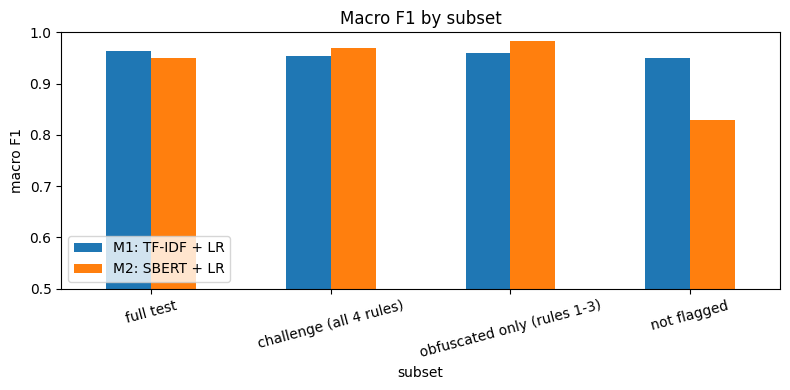

In [21]:
piv = sub_res.pivot(index="subset", columns="method", values="macro_F1").loc[
    ["full test", "challenge (all 4 rules)", "obfuscated only (rules 1-3)", "not flagged"]]
piv.plot(kind="bar", figsize=(8, 4), ylim=(0.5, 1.0), rot=15, title="Macro F1 by subset")
plt.ylabel("macro F1"); plt.legend(loc="lower left"); plt.tight_layout(); plt.show()

In [22]:
# spam caught inside the challenge subset, and false alarms on ham that contains a spam keyword
ch = test_df[test_df["challenge"] & (test_df["y"] == 1)]
print("spam msgs in challenge subset:", len(ch))
print("M1 caught:", int(ch["pred1"].sum()), " | M2 caught:", int(ch["pred2"].sum()))

hc = test_df[test_df["keyword"] & (test_df["y"] == 0)]
print("\nham msgs that contain a spam keyword:", len(hc))
print("M1 false alarms:", int(hc["pred1"].sum()), " | M2 false alarms:", int(hc["pred2"].sum()))

spam msgs in challenge subset: 81
M1 caught: 75  | M2 caught: 78

ham msgs that contain a spam keyword: 17
M1 false alarms: 3  | M2 false alarms: 3


**Our first observation:** Sentence-BERT does better on the selected challenge messages in this split, while TF-IDF does better on messages that were not selected. Since the difference is only a few messages, we do not rely on this result alone. The next sections check it in other ways.

### 6.3 Extra test: changing letters in spam messages

We create another test by replacing some letters in the spam messages. For example, we may replace `e` with `3`, `i` with `1`, or `a` with `4`. The replacement probability is controlled by `p`.

The models are not trained again on these altered messages. We measure spam recall: the proportion of spam messages that each model still identifies as spam.

In [23]:
spam_test = test_df[test_df["y"] == 1]["text"].tolist()
rows = []
for p in P_LEVELS:
    rng = np.random.default_rng(SEED)
    obf = [leetify(t, p, rng) for t in spam_test]
    rows.append({"p_replace": p,
                 "M1 spam recall": round(m1.predict(tfidf.transform(obf)).mean(), 3),
                 "M2 spam recall": round(m2.predict(embed(obf)).mean(), 3)})
leet_res = pd.DataFrame(rows)
print("example (p=0.25):", leetify(spam_test[0], 0.25, np.random.default_rng(SEED)))
leet_res

example (p=0.25): WINNER!! As 4 valued netw0rk customer you have b3en 5elected to receiv3a £900 pr1z3 reward! To claim call 09061701461. Cl41m cod3 KL341. Valid 12 hours only.


,p_replace,M1 spam recall,M2 spam recall
0,0.00,0.927,0.927
1,0.10,0.927,0.938
2,0.25,0.906,0.938
3,0.50,0.823,0.969


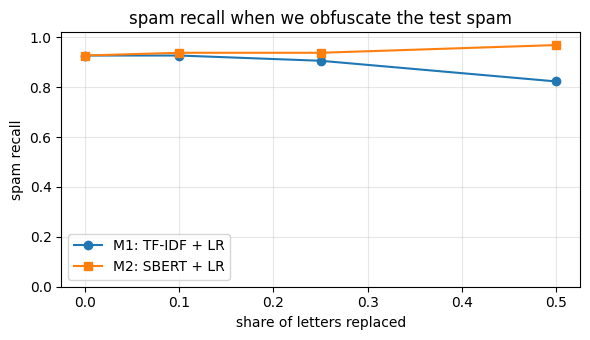

In [24]:
plt.figure(figsize=(6, 3.5))
plt.plot(leet_res["p_replace"], leet_res["M1 spam recall"], "o-", label="M1: TF-IDF + LR")
plt.plot(leet_res["p_replace"], leet_res["M2 spam recall"], "s-", label="M2: SBERT + LR")
plt.xlabel("share of letters replaced"); plt.ylabel("spam recall"); plt.ylim(0, 1.02)
plt.title("spam recall when we obfuscate the test spam"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

**What we noticed:** as more letters are changed, TF-IDF misses more spam messages. This makes sense because the altered words may not match the words it learned during training. Sentence-BERT keeps a higher spam recall in this experiment.

### 6.4 Extra test: changing letters in normal messages

We also apply the same changes to normal messages. This is important because a useful spam detector should not label every unusual-looking message as spam.

Here we report the false alarm rate: the proportion of normal messages that are incorrectly predicted as spam.

In [25]:
ham_test = test_df[test_df["y"] == 0]["text"].tolist()
rows = []
for p in P_LEVELS:
    rng = np.random.default_rng(SEED)
    obf = [leetify(t, p, rng) for t in ham_test]
    rows.append({"p_replace": p,
                 "M1 false alarm rate": round(m1.predict(tfidf.transform(obf)).mean(), 3),
                 "M2 false alarm rate": round(m2.predict(embed(obf)).mean(), 3)})
leet_ham_res = pd.DataFrame(rows)
print("ham messages:", len(ham_test))
leet_ham_res

ham messages: 678


,p_replace,M1 false alarm rate,M2 false alarm rate
0,0.00,0.007,0.015
1,0.10,0.009,0.024
2,0.25,0.015,0.052
3,0.50,0.025,0.119


**What we noticed:** TF-IDF has a lower false alarm rate in this test. Sentence-BERT catches more of the heavily altered spam, but it also marks more altered normal messages as spam. So we need to consider both spam recall and false alarms.

### 6.5 Checking whether the difference is meaningful

Both models predict the same test messages, so we use the exact McNemar test. It focuses on messages where the models disagree. We count cases where only Method 1 is correct (`b`) and cases where only Method 2 is correct (`c`).

We use 0.05 as the significance level. A p-value below 0.05 suggests that the difference is unlikely to be explained by random disagreement alone.

In [26]:
rows = []
for name, mask in [("full test", np.ones(len(test_df), bool)),
                   ("challenge (all 4 rules)", test_df["challenge"].values),
                   ("obfuscated only (rules 1-3)", test_df["obfuscated"].values)]:
    b, c, pv = mcnemar(test_df["y"].values[mask], pred1[mask], pred2[mask])
    rows.append({"subset": name, "M1 right / M2 wrong (b)": b, "M1 wrong / M2 right (c)": c, "p-value": round(pv, 3)})

# the 96 test spam messages with 50% of letters replaced (same messages for both models)
rng = np.random.default_rng(SEED)
obf_spam = [leetify(t, 0.5, rng) for t in spam_test]
b, c, pv = mcnemar(np.ones(len(obf_spam), int), m1.predict(tfidf.transform(obf_spam)), m2.predict(embed(obf_spam)))
rows.append({"subset": "spam, 50% letters obfuscated", "M1 right / M2 wrong (b)": b, "M1 wrong / M2 right (c)": c, "p-value": round(pv, 3)})

mcnemar_res = pd.DataFrame(rows)
mcnemar_res

,subset,M1 right / M2 wrong (b),M1 wrong / M2 right (c),p-value
0,full test,13,8,0.383
1,challenge (all 4 rules),3,6,0.508
2,obfuscated only (rules 1-3),1,5,0.219
3,"spam, 50% letters obfuscated",2,16,0.001


**What we found:** for the original test messages and the two rule-based subsets, the p-values are above 0.05. We therefore do not have enough evidence to say that one model is significantly better on those groups. The heavy synthetic spam-obfuscation test is different: Sentence-BERT catches more of those altered spam messages.

### 6.6 Repeating the experiment with five random splits

A result from one train/test split can depend on which messages happen to be selected. To check this, we repeat the full process with five random seeds. For each seed, we create new splits, tune the settings on the development set and evaluate on that seed's test set.

The Sentence-BERT embeddings are calculated once because the embeddings for a message do not change when the data split changes.

In [27]:
E_all   = embed(df["text"].tolist())
fl_all  = pd.DataFrame([flags(t) for t in df["text"]])
ch_all  = fl_all.any(axis=1).values
ob_all  = fl_all[["digit_in_word", "repeat", "no_vowel"]].any(axis=1).values
y_all   = df["y"].values
txt_all = df["text"].values

def run_seed(seed):
    idx = np.arange(len(df))
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=seed)
    dv, te  = train_test_split(tmp, test_size=0.50, stratify=y_all[tmp], random_state=seed)

    # method 1: tune C and min_df on dev
    best = (-1, None)
    for min_df in MIN_DF_GRID:
        for C in C_GRID:
            vec = make_tfidf(min_df)
            clf = make_lr(C, seed, 2000).fit(vec.fit_transform(txt_all[tr]), y_all[tr])
            f = macro_f1(y_all[dv], clf.predict(vec.transform(txt_all[dv])))
            if f > best[0]: best = (f, (vec, clf, C))
    vec, clf1, c1 = best[1]
    p1 = clf1.predict(vec.transform(txt_all[te]))

    # method 2: tune C on dev
    best = (-1, None)
    for C in C_GRID:
        clf = make_lr(C, seed, 5000).fit(E_all[tr], y_all[tr])
        f = macro_f1(y_all[dv], clf.predict(E_all[dv]))
        if f > best[0]: best = (f, (clf, C))
    clf2, c2 = best[1]
    p2 = clf2.predict(E_all[te])

    yt, ch, ob = y_all[te], ch_all[te], ob_all[te]
    return {"seed": seed, "M1 best C": c1, "M2 best C": c2,
            "M1 full F1": macro_f1(yt, p1), "M2 full F1": macro_f1(yt, p2),
            "M1 challenge F1": macro_f1(yt[ch], p1[ch]), "M2 challenge F1": macro_f1(yt[ch], p2[ch]),
            "M1 obfuscated F1": macro_f1(yt[ob], p1[ob]), "M2 obfuscated F1": macro_f1(yt[ob], p2[ob])}

seed_res = pd.DataFrame([run_seed(s) for s in SEEDS]).round(4)
seed_res

,seed,M1 best C,M2 best C,M1 full F1,M2 full F1,M1 challenge F1,M2 challenge F1,M1 obfuscated F1,M2 obfuscated F1
0,42,100,100,0.9640,0.9501,0.9538,0.9694,0.9598,0.9829
1,1,100,100,0.9764,0.9708,0.9802,0.9754,0.9783,0.9784
2,7,100,100,0.9789,0.9479,0.9843,0.9530,0.9879,0.9574
3,21,10,10,0.9726,0.9426,0.9784,0.9626,0.9813,0.9630
4,100,10,10,0.9700,0.9795,0.9698,0.9851,0.9831,0.9888


    subset  M1 mean  M1 std  M2 mean  M2 std  M2 better in (of 5)
      full   0.9724  0.0058   0.9582  0.0160                    1
 challenge   0.9733  0.0121   0.9691  0.0122                    2
obfuscated   0.9781  0.0108   0.9741  0.0134                    3


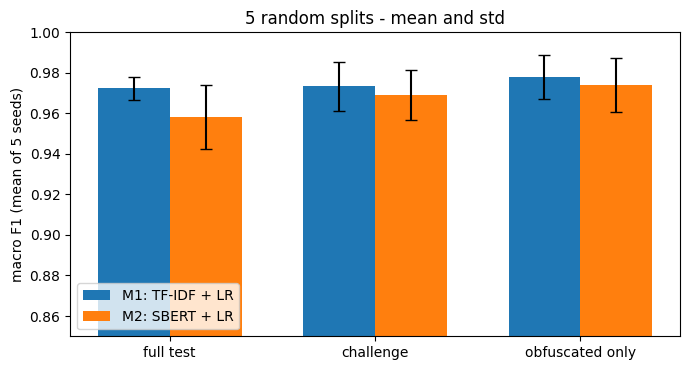

In [28]:
cols = ["full", "challenge", "obfuscated"]
summary = pd.DataFrame({
    "subset": cols,
    "M1 mean": [seed_res[f"M1 {c} F1"].mean() for c in cols],
    "M1 std":  [seed_res[f"M1 {c} F1"].std() for c in cols],
    "M2 mean": [seed_res[f"M2 {c} F1"].mean() for c in cols],
    "M2 std":  [seed_res[f"M2 {c} F1"].std() for c in cols],
    "M2 better in (of 5)": [int((seed_res[f"M2 {c} F1"] > seed_res[f"M1 {c} F1"]).sum()) for c in cols],
}).round(4)
print(summary.to_string(index=False))

x = np.arange(len(cols)); w = 0.35
plt.figure(figsize=(7, 3.8))
plt.bar(x - w/2, summary["M1 mean"], w, yerr=summary["M1 std"], capsize=4, label="M1: TF-IDF + LR")
plt.bar(x + w/2, summary["M2 mean"], w, yerr=summary["M2 std"], capsize=4, label="M2: SBERT + LR")
plt.xticks(x, ["full test", "challenge", "obfuscated only"]); plt.ylim(0.85, 1.0)
plt.ylabel("macro F1 (mean of 5 seeds)"); plt.title("5 random splits - mean and std")
plt.legend(loc="lower left"); plt.tight_layout(); plt.show()

**What we found:** the five runs give a more balanced picture than the first split alone. TF-IDF has a slightly higher average macro F1 in these runs, while Sentence-BERT is better in some individual runs. This is why we avoid saying that Sentence-BERT is always better on misspelled messages.

## 7. Looking at the mistakes

In this section, we list the messages each model classified incorrectly. Looking at individual examples helps us understand why a model can make a mistake even when its overall score is high.

In [29]:
def errors_of(pred_col):
    e = test_df[test_df[pred_col] != test_df["y"]][["label", "text", "challenge"]].copy()
    e["M1_pred"] = np.where(test_df.loc[e.index, "pred1"] == 1, "spam", "ham")
    e["M2_pred"] = np.where(test_df.loc[e.index, "pred2"] == 1, "spam", "ham")
    return e

err1 = errors_of("pred1")
print("M1 errors:", len(err1))
err1

M1 errors: 12


,label,text,challenge,M1_pred,M2_pred
1029,ham,I'm at work. Please call,False,spam,ham
152,ham,Ok... Ur typical reply...,False,spam,ham
3327,spam,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S...",True,ham,spam
1230,spam,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£...,True,ham,spam
3173,spam,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,False,ham,ham
2967,spam,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better...",True,ham,spam
2196,ham,Dont you have message offer,True,spam,spam
5130,spam,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,True,ham,spam
2326,spam,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your op...,True,ham,ham
1456,ham,Total video converter free download type this in google search:),True,spam,ham


In [30]:
err2 = errors_of("pred2")
print("M2 errors:", len(err2))
err2

M2 errors: 17


,label,text,challenge,M1_pred,M2_pred
3267,ham,i am seeking a lady in the street and a freak in the sheets. Is that you?,False,ham,spam
612,ham,MAKE SURE ALEX KNOWS HIS BIRTHDAY IS OVER IN FIFTEEN MINUTES AS FAR AS YOU'RE CONCERNED,False,ham,spam
1926,spam,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the n...,True,spam,ham
3383,ham,I've sent my wife your text. After we buy them she'll tell you what to do. So just relax. We should go get them this...,False,ham,spam
3655,ham,Unlimited texts. Limited minutes.,False,ham,spam
3606,ham,Early bird! Any purchases yet?,False,ham,spam
4988,ham,Its sunny in california. The weather's just cool,False,ham,spam
3811,ham,"Aight I've been set free, think you could text me blake's address? It occurs to me I'm not quite as sure what I'm do...",True,ham,spam
1828,spam,"FreeMsg Hey U, i just got 1 of these video/pic fones, reply WILD to this txt & ill send U my pics, hurry up Im so bo...",True,spam,ham
3173,spam,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,False,ham,ham


In [31]:
both = set(err1.index) & set(err2.index)
print("wrong in both:", len(both), "| only M1:", len(set(err1.index) - both), "| only M2:", len(set(err2.index) - both))

wrong in both: 4 | only M1: 8 | only M2: 13


### 7.1 Examples of Method 1 mistakes

The examples below show some of the types of mistakes made by TF-IDF. Short messages can be difficult because one word may have a strong effect. Chat-style spam can also look like normal texting, and unusual spellings may not match the vocabulary learned by TF-IDF. We also found a normal message containing words such as “free” and “download” that was classified as spam.

### 7.2 Examples of Method 2 mistakes

Sentence-BERT sometimes marks normal messages as spam when their meaning is close to promotional language. Short and neutral messages can also be difficult because there is not much context in them. On the other hand, it can understand some misspelled messages better than TF-IDF. The examples show that the two methods make different mistakes, rather than one model fixing every error made by the other.

Only four messages were classified incorrectly by both methods. This suggests that the models have different strengths and weaknesses.

## 8. Try the models on a new message

The function below takes a message and returns the prediction from TF-IDF, Sentence-BERT or both. It also prints the estimated spam probability. The models are already trained, so this part does not train them again.

In [32]:
def classify(msg, method="both"):
    msg = (msg or "").strip()
    if not msg:
        return "Please type a message (input was empty)."
    p1 = m1.predict_proba(tfidf.transform([msg]))[0, 1]
    p2 = m2.predict_proba(embed([msg]))[0, 1]
    lab = lambda p: "Spam" if p >= 0.5 else "Not spam"
    if method == "tfidf": return f"TF-IDF+LR: {lab(p1)} (p_spam={p1:.2f})"
    if method == "sbert": return f"SBERT+LR: {lab(p2)} (p_spam={p2:.2f})"
    return f"TF-IDF+LR: {lab(p1)} (p_spam={p1:.2f}) | SBERT+LR: {lab(p2)} (p_spam={p2:.2f})"

print(classify("You won a cash prize. Pay a fee now to claim it"))
print(classify(""))

TF-IDF+LR: Spam (p_spam=1.00) | SBERT+LR: Spam (p_spam=0.99)
Please type a message (input was empty).


### 8.1 Our own labelled examples
Messages we wrote ourselves (not from the dataset), with the label we expect. The first four are plain messages (written in Arabic and translated to English); the last four are obfuscated, two spam and two ham, to test our question directly.

In [33]:
own = pd.DataFrame([
    ("Hey! How are you? Hope you're doing well ❤️", "ham"),
    ("Congratulations! Your number has been selected to win a cash prize of 5,000 SAR. Click here to claim your prize now!", "spam"),
    ("Assalamu alaikum, how are you doing? Hope to see you soon inshallah", "ham"),
    ("Congrats! You won a FREE iPhone 17! Click the link to confirm your details and get your prize", "spam"),
    ("C0ngr4ts! Y0u'v3 b33n ch0s3n t0 r3c31v3 a $500 g1ft c4rd.", "spam"),
    ("Cl@im y0ur c4sh rew4rd n0w b3f0r3 1t's g0n3!", "spam"),
    ("H3y, c4n y0u s3nd m3 th3 f1l3 b3f0r3 t0m0rr0w's cl4ss?", "ham"),
    ("I'll b3 l4t3 t0d4y, pl34s3 w41t f0r m3.", "ham"),
], columns=["text", "expected"])

own["M1"] = np.where(m1.predict(tfidf.transform(own["text"])) == 1, "spam", "ham")
own["M2"] = np.where(m2.predict(embed(own["text"].tolist())) == 1, "spam", "ham")
own

,text,expected,M1,M2
0,Hey! How are you? Hope you're doing well ❤️,ham,ham,ham
1,"Congratulations! Your number has been selected to win a cash prize of 5,000 SAR. Click here to claim your prize now!",spam,spam,spam
2,"Assalamu alaikum, how are you doing? Hope to see you soon inshallah",ham,ham,ham
3,Congrats! You won a FREE iPhone 17! Click the link to confirm your details and get your prize,spam,spam,spam
4,C0ngr4ts! Y0u'v3 b33n ch0s3n t0 r3c31v3 a $500 g1ft c4rd.,spam,spam,spam
5,Cl@im y0ur c4sh rew4rd n0w b3f0r3 1t's g0n3!,spam,ham,spam
6,"H3y, c4n y0u s3nd m3 th3 f1l3 b3f0r3 t0m0rr0w's cl4ss?",ham,ham,ham
7,"I'll b3 l4t3 t0d4y, pl34s3 w41t f0r m3.",ham,ham,ham


In [ ]:
# interactive box: type a message and press Enter, an empty line stops it
try:
    while True:
        s = input("SMS> ")
        print(classify(s))
        if s.strip() == "":
            break
except (EOFError, KeyboardInterrupt):
    pass

SMS> C0ngr4ts! Y0u'v3 b33n ch0s3n… $500 g1ft c4rd
TF-IDF+LR: Spam (p_spam=0.69) | SBERT+LR: Spam (p_spam=0.96)
SMS> H3y, c4n y0u s3nd m3 th3 f1l3…
TF-IDF+LR: Not spam (p_spam=0.02) | SBERT+LR: Not spam (p_spam=0.00)


## 9. Conclusion

The results suggest that there is no single winner for every situation.

- On the full test set, TF-IDF + Logistic Regression has the higher macro F1 score for this split.
- Sentence-BERT performs better on the rule-based challenge subset in the first split, but the difference is not statistically significant.
- When we replace many letters in spam messages, Sentence-BERT keeps a higher spam recall. However, it also produces more false alarms on altered normal messages.
- Across five random splits, TF-IDF has a slightly higher average macro F1 overall.

**Our answer to the research question:** Sentence-BERT is more resistant to the strong letter substitutions we created, but this does not mean it is always better at detecting real misspelled spam. TF-IDF is a strong and simpler option for the full dataset, while Sentence-BERT may be useful when the spelling is heavily changed.

### Limitations

- The challenge subset is based on simple rules. Some normal messages contain patterns such as `txt`, `msg` or spam-related keywords, so the subset is not made up of spam only.
- Our letter replacement experiment is synthetic and may not represent every way real spammers hide words.
- We use a 0.5 decision threshold for both models and do not tune the threshold.
- The results come from one SMS dataset, so they may not transfer directly to other languages or newer messages.

A useful next step would be to test character-level features and collect more recent SMS examples.

## 10. Saving the results

The next cell saves the main result tables and the test-set errors as CSV files in a `results` folder. This makes it easier to use the numbers later in the report.

In [ ]:
os.makedirs("results", exist_ok=True)
tables = {"dev_tuning_tfidf": m1_tab, "dev_tuning_sbert": m2_tab, "test_results": results,
          "subset_results": sub_res, "leet_test": leet_res, "leet_ham_test": leet_ham_res,
          "mcnemar": mcnemar_res, "five_seeds": seed_res, "five_seeds_summary": summary}
for name, t in tables.items():
    t.to_csv(f"results/{name}.csv", index=False)
test_df.loc[sorted(set(err1.index) | set(err2.index)), ["label", "text", "pred1", "pred2", "challenge"]] \
    .rename(columns={"pred1": "M1_pred", "pred2": "M2_pred"}).to_csv("results/test_errors.csv")
print(sorted(os.listdir("results")))

## 11. Sources

1. T. A. Almeida, J. M. G. Hidalgo, and A. Yamakami, “Contributions to the study of SMS spam filtering: new collection and results,” *Proceedings of the 11th ACM Symposium on Document Engineering*, 2011, pp. 259–262. Dataset: https://archive.ics.uci.edu/dataset/228/sms+spam+collection
2. N. Reimers and I. Gurevych, “Sentence-BERT: Sentence embeddings using Siamese BERT-networks,” *Proceedings of EMNLP-IJCNLP*, 2019, pp. 3982–3992. Model: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2

**Main libraries:** pandas, NumPy, scikit-learn, sentence-transformers, SciPy and Matplotlib.
